### Задача 1

Импортируйте файл Event_click.xlsx.\
В нем содержатся результаты A/B теста, который проводился в онлайн-кинотеатре. В рамках эксперимента тестировалась новая рекомендательная система, цель которой - убедить пользователя просмотреть тот или иной тайтл.\

Описание данных:
- id_client - уникальный идентификатор клиента
- dtime_event - дата совершения события (временная часть опущена для облегчения данных)
- flag_group - флаг принадлежности к тестовой группе (1 - тест, 0 -контроль).
- event - залогированное клиентское событие (play - пригрывание плеера, click - клик мышкой, scroll - прокручивание страницы)

Необходимо подготовить данные к анализу результатов A/B теста.\
Для этого:
1. Определите количество нуллов в рамках каждого столбца (и их пересечений) и исключите все записи, в которых отсутствует информация хотя бы в одном поле.
2. Выявите клиентов, которые в течение эксперимента попадали в разные группы (*Подсказка: рассчитайте количество уникальных значений поля flag_group на каждого клиента*)
3. Исключите этих клиентов из выборки.
4. Оцените общее количество исключений (относительно всей выборки)


In [62]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

event_click = pd.read_excel('Event_click.xlsx')
event_click.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10554 entries, 0 to 10553
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id_client    10460 non-null  float64       
 1   dtime_event  10554 non-null  datetime64[ns]
 2   flag_group   10162 non-null  float64       
 3   event        10041 non-null  object        
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 329.9+ KB


In [37]:
event_click_clean  = event_click.dropna() #удалили нули
event_click_clean

,id_client,dtime_event,flag_group,event
0,1012904.0,2024-01-04,1.0,scroll
1,1009690.0,2024-01-25,0.0,click
2,1014159.0,2024-01-24,1.0,scroll
3,1010542.0,2024-01-23,0.0,play
4,1013213.0,2024-01-20,0.0,scroll
...,...,...,...,...
10549,1010732.0,2024-01-17,0.0,play
10550,1016775.0,2024-01-27,1.0,click
10551,1015741.0,2024-01-07,1.0,click
10552,1009960.0,2024-01-12,0.0,play


In [24]:
event_click_new = event_click_clean.groupby(['id_client']).agg(cnt = ('flag_group','nunique')).reset_index()

event_id_list = list(event_click_new[event_click_new['cnt'] == 1]['id_client'])

In [26]:
event_click_final = event_click_clean[event_click_clean['id_client'].isin(event_id_list)]


In [133]:
print('Доля исключений', round((1 - len(event_click_final)/len(event_click))*100, 2),'%')

print('Количество исключений', len(event_click) - len(event_click_final))

Доля исключений 7.37 %
Количество исключений 778


## Задача 2

Задача новой рекомендательной системы заключается в том, чтобы повысить процент людей, которые при заходе на нашу страницу (то есть при совершении любого действия) перейдут в плеер (то есть совершат действие play).

Рассчитайте отдельно для *контрольной* и *тестовой* группы процент пользователей, которые совершили хотя бы одно действие play. Можете ли вы сделать вывод о значимом улучшении конверсии в просмотр?

Обратите внимание, что в Задании 2 мы работаем с очищенными данными, полученными в результате выполнения Задания 1.

Алгоритм решения:

+ создайте в данных новую колонку flag_play, которая принимает значение 1, если совершаемое действие - ‘play’ и 0 для любого другого действия


+ сгруппируйте данные по двум столбцам одновременно - пользователь и его группа - и посчитайте максимальное значение по колонке flag_play (если пользователь хотя бы раз играл, то максимальное значение будет 1, если ни разу, то окажется 0), назовем его max_flag


+ возьмите среднее значение max_flag  для тестовой и контрольной групп - отличаются ли значения?


+ проведите t-тест по колонке max_flag для тестовой и контрольной групп, чтобы оценить стат. значимость разницы в средних значениях между ними. Воспользуйтесь функцией ttest_ind.

In [42]:
event_click_final['flag_play'] = np.where(event_click_final['event'] == 'play',1,0)
event_click_final

event_click_play = event_click_final.groupby(['id_client','flag_group']).agg(max_flag = ('flag_play','max')).reset_index()

event_click_play.groupby('flag_group')['max_flag'].mean().reset_index()
print() #


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_59976/4256758306.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_click_final['flag_play'] = np.where(event_click_final['event'] == 'play',1,0)


,flag_group,max_flag
0,0.0,0.283344
1,1.0,0.314716


In [151]:
from scipy import stats 

gr0 = event_click_play[event_click_play['flag_group'] == 1]
gr1 = event_click_play[event_click_play['flag_group'] == 0]

s, p = stats.ttest_ind(gr0['max_flag'], gr1['max_flag'])  
print('s=',s)  
print('p=',p)
print('Различия статистически значимы, в группе "тест" среднее выше') 

s= 2.655959605685953
p= 0.00792921558490156
Различия статистически значимы, в группе "тест" среднее выше


## Задача 3

Рассчитайте DAU и WAU по имеющимся данным.\
Допустим, активностью пользователя является любая активность (совершение любого действия, хотя бы одного).\

1. Рассчитайте и визуализируйте DAU (по оси Х - дни)
2. Рассчитайте и визуализируйте WAU (по оси Х - недели) (*исключите неполные недели*)
3. Соедините DAU и WAU и визуализируйте их на одном графике (по оси Х - дни)

Какие выводы можно сделать на основании имеющихся данных?

*Подсказка: чтобы определить номер недели в году используйте метод isocalendar()*\
*Ознакомиться с документацией можно по ссылке: https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.isocalendar.html*

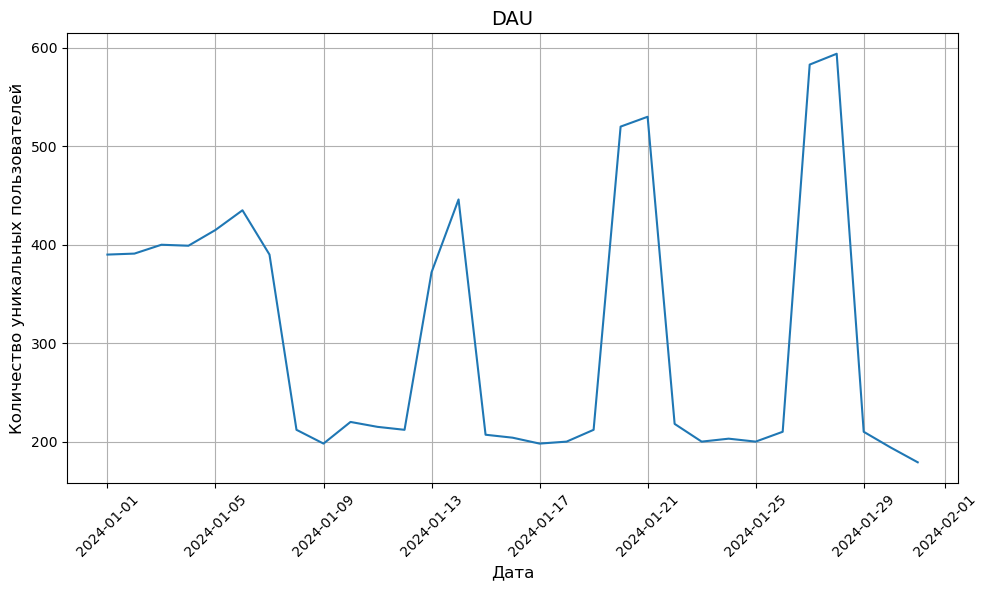

In [102]:
DAU = event_click_final.groupby('dtime_event').agg(DAU = ('id_client','nunique')).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(DAU['dtime_event'], DAU['DAU'])
plt.title('DAU', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество уникальных пользователей', fontsize=12)
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_59976/4200079450.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_click_final['week'] = pd.to_datetime(event_click_final['dtime_event']).dt.isocalendar().week


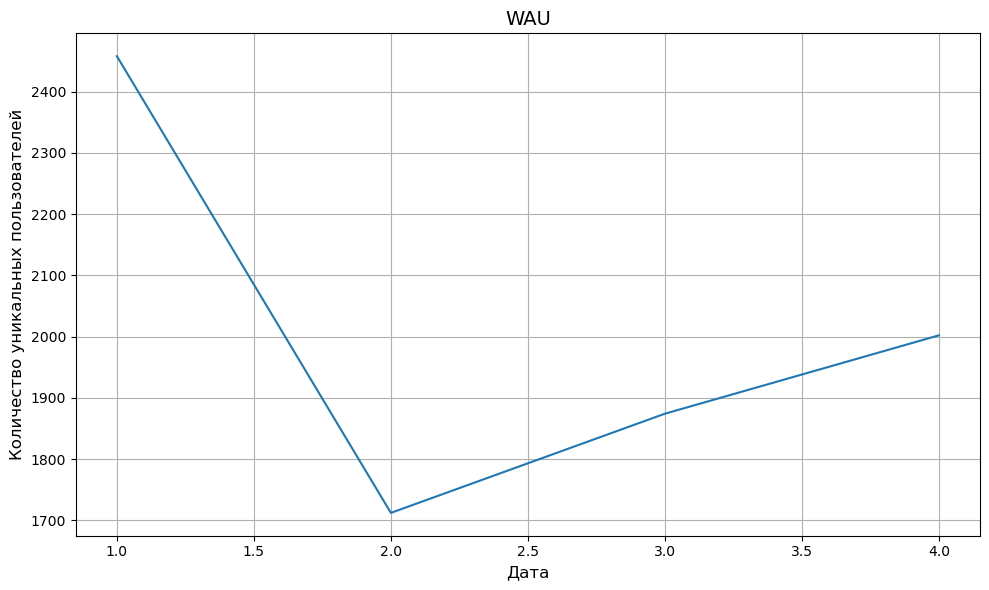

In [85]:
event_click_final['week'] = pd.to_datetime(event_click_final['dtime_event']).dt.isocalendar().week

filtered_data = event_click_final[event_click_final['week'] != 5]
WAU = filtered_data.groupby('week').agg(WAU = ('id_client','nunique')).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(WAU['week'], WAU['WAU'])
plt.title('WAU', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество уникальных пользователей', fontsize=12)
plt.grid()
plt.tight_layout()
plt.show()


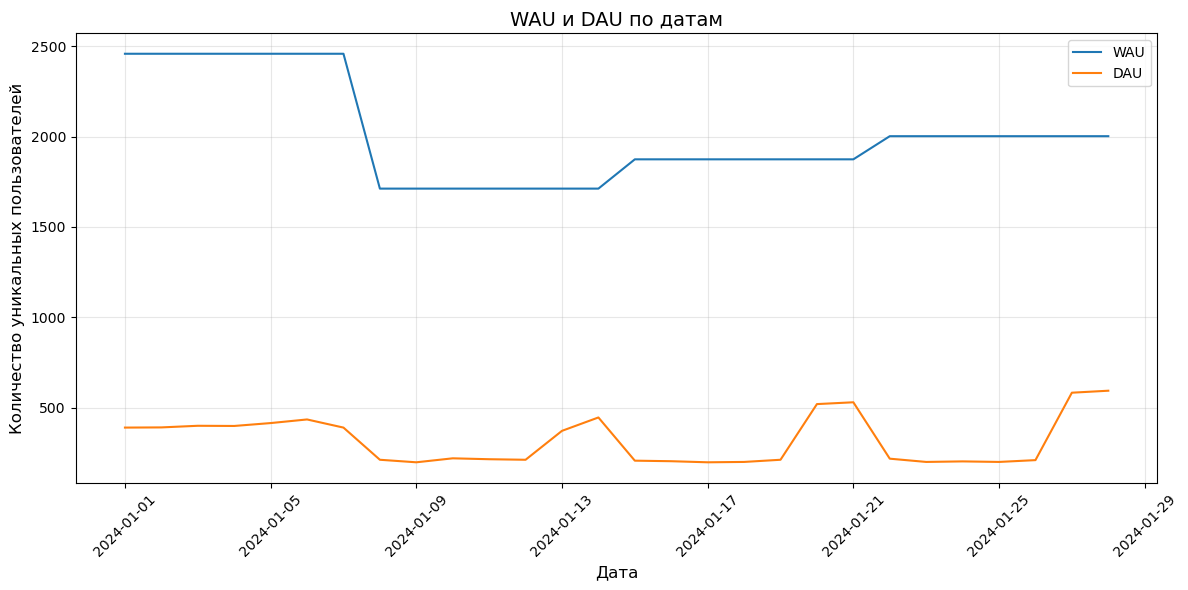

In [111]:
DAU_copy = DAU.copy()
DAU_copy['week'] = pd.to_datetime(DAU_copy['dtime_event']).dt.isocalendar().week

# Объединяем по новому столбцу
new = WAU.merge(DAU_copy, on='week')

plt.figure(figsize=(12, 6))
plt.plot(new['dtime_event'], new['WAU'], markersize=4, label='WAU')
plt.plot(new['dtime_event'], new['DAU'], markersize=4, label='DAU')
plt.title('WAU и DAU по датам', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество уникальных пользователей', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Вывод: WAU поверхностно повторяет DAU, которое более детально показывает колебания 
В конце каждой недели происходят резкие скачки вниз в начале года, 
далее - с каждой неделей выше и выше

## Дополнительная задача

Изменятся ли выводы, если поменять определение "активности"? \
В качестве "активности" возьмите действие play (то есть остальные действия не считаются за "клиентскую активность", в отличие от Задачи-3)

In [125]:
event_click_final_play_no5 = filtered_data[filtered_data['event'] == 'play']
event_click_final_play = event_click_final[event_click_final['event'] == 'play']
WAU = event_click_final_play_no5.groupby('week').agg(WAU = ('id_client','nunique')).reset_index()
DAU = event_click_final_play.groupby('dtime_event').agg(DAU = ('id_client','nunique')).reset_index()
DAU_copy = DAU.copy()
DAU_copy['week'] = pd.to_datetime(DAU_copy['dtime_event']).dt.isocalendar().week

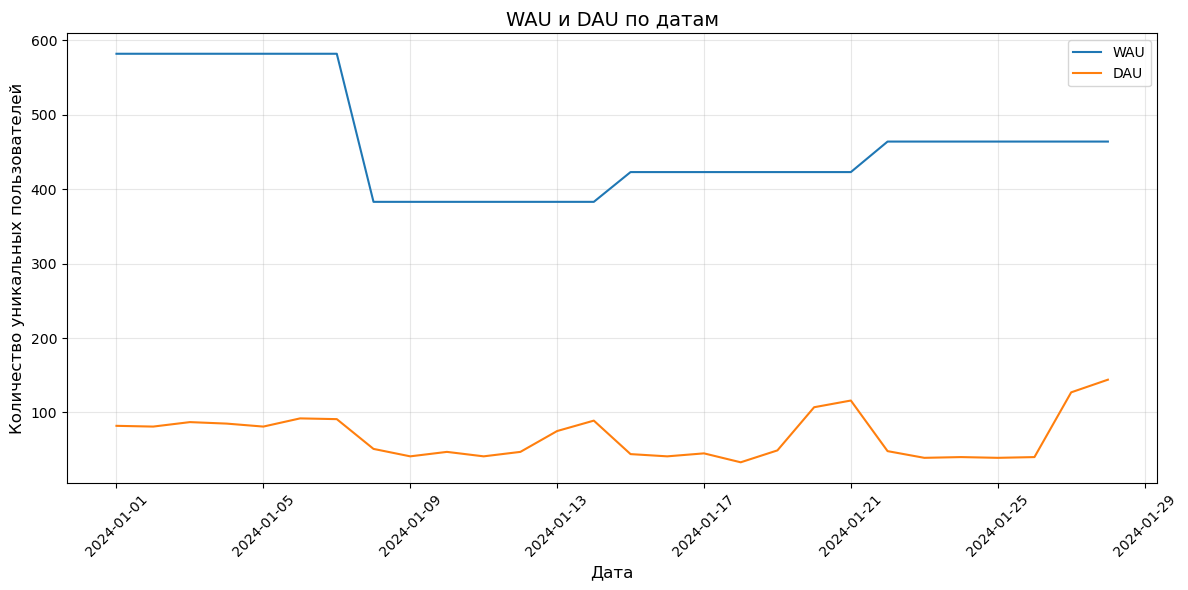

In [127]:
new = WAU.merge(DAU_copy, on='week')

plt.figure(figsize=(12, 6))
plt.plot(new['dtime_event'], new['WAU'], markersize=4, label='WAU')
plt.plot(new['dtime_event'], new['DAU'], markersize=4, label='DAU')
plt.title('WAU и DAU по датам', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество уникальных пользователей', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Динамика не изменилась, но наблюдений стало меньше 
- если до выборки play наблюдений DAU было около 500, после - около 100